In [1]:
print("Welcome to EquipmentIQ!")
name = "Industrial Energy Anomaly Detection"
print("Project:", name)
print("Environment is working successfully!")

Welcome to EquipmentIQ!
Project: Industrial Energy Anomaly Detection
Environment is working successfully!


In [2]:
from pathlib import Path
# Keeping all project files organised in separate folders.
project_folder = Path.cwd()
required_folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "src/api",
    "src/core",
    "src/models",
    "src/services",
    "tests"
]
# Created folders if they do not already exist.
for folder in required_folders:
    folder_path = project_folder / folder
    folder_path.mkdir(parents=True, exist_ok=True)

print("EquipmentIQ project structure is ready!")
# Display the folders. 
for folder in required_folders:
    print(f"Created: {folder}")

EquipmentIQ project structure is ready!
Created: data/raw
Created: data/processed
Created: notebooks
Created: src/api
Created: src/core
Created: src/models
Created: src/services
Created: tests


In [3]:
from pathlib import Path
# Define the project directory.
project_dir = Path.cwd()

# Define the application structure.
folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "src/api",
    "src/core",
    "src/models",
    "src/services",
    "tests"
]

# Create the required directories.
for folder in folders:
    (project_dir / folder).mkdir(parents=True, exist_ok=True)

In [4]:
import numpy as np
import pandas as pd
from pathlib import Path

# Use a fixed random seed so the dataset is reproducible.
rng = np.random.default_rng(42)

# Generate timestamps for seven days at one-minute intervals.
timestamps = pd.date_range(start="2026-01-01",periods=7 * 24 * 60,freq="min")

# Assign equipment operating status based on the time of day.
hour = timestamps.hour
status = np.select([(hour >= 6) & (hour < 22),((hour >= 5) & (hour < 6)) | ((hour >= 22) & (hour < 23))],["RUNNING", "STANDBY"],default="OFF")

# Generate ambient temperature with a daily temperature cycle.
ambient_temp = (27+4*np.sin(2*np.pi*(hour-6)/24)+ rng.normal(0,0.5,len(timestamps)))

# Generate sensor readings based on equipment status.
power_kw = np.select([status == "RUNNING", status == "STANDBY"],[150 + rng.normal(0, 5, len(timestamps)),35 + rng.normal(0, 2, len(timestamps))],default=2 + rng.normal(0, 0.3, len(timestamps)))
flow_rate_gpm = np.select(
    [status == "RUNNING", status == "STANDBY"],[500 + rng.normal(0, 15, len(timestamps)),100 + rng.normal(0,5,len(timestamps))],default=0)
supply_temp_c = np.select(
    [status == "RUNNING", status == "STANDBY"],[6.5 + rng.normal(0, 0.3, len(timestamps)),10 + rng.normal(0, 0.5, len(timestamps))],default=ambient_temp - 1)
return_temp_c = np.select([status == "RUNNING", status == "STANDBY"],[12.5 + rng.normal(0, 0.4, len(timestamps)),
        13 + rng.normal(0, 0.5, len(timestamps))],default=ambient_temp)

# Assemble the sensor readings into a DataFrame.
df = pd.DataFrame({
    "timestamp": timestamps,
    "power_kw": power_kw,
    "flow_rate_gpm": flow_rate_gpm,
    "supply_temp_c": supply_temp_c,
    "return_temp_c": return_temp_c,
    "ambient_temp_c": ambient_temp,
    "status": status
})

# Save the raw dataset.
output_path = Path("data/raw/industrial_energy_data.csv")
df.to_csv(output_path, index=False)

# Inspect the generated dataset.
display(df.head())
display(df.shape)
display(df["status"].value_counts())

,timestamp,power_kw,flow_rate_gpm,supply_temp_c,return_temp_c,ambient_temp_c,status
0,2026-01-01 00:00:00,1.524463,0.0,22.152359,23.152359,23.152359,OFF
1,2026-01-01 00:01:00,2.019748,0.0,21.480008,22.480008,22.480008,OFF
2,2026-01-01 00:02:00,2.233028,0.0,22.375226,23.375226,23.375226,OFF
3,2026-01-01 00:03:00,1.926057,0.0,22.470282,23.470282,23.470282,OFF
4,2026-01-01 00:04:00,2.269036,0.0,21.024482,22.024482,22.024482,OFF


(10080, 7)

status
RUNNING    6720
OFF        2520
STANDBY     840
Name: count, dtype: int64

In [5]:
# Identify continuous operating periods.
running_data = df[df["status"] == "RUNNING"]
print("Running records:", len(running_data))
print("First running timestamp:",running_data["timestamp"].min())
print("Last running timestamp:",running_data["timestamp"].max())

Running records: 6720
First running timestamp: 2026-01-01 06:00:00
Last running timestamp: 2026-01-07 21:59:00


In [6]:
# Inject a sudden power spike during normal operation.
spike_start = pd.Timestamp("2026-01-02 10:00:00")
spike_end = pd.Timestamp("2026-01-02 10:10:00")
spike_mask = ((df["timestamp"]>=spike_start) & (df["timestamp"]<=spike_end) & (df["status"]=="RUNNING"))
df.loc[spike_mask,"power_kw"]*= 2.5

In [7]:
df.loc[spike_mask,["timestamp", "power_kw", "flow_rate_gpm"]]

,timestamp,power_kw,flow_rate_gpm
2040,2026-01-02 10:00:00,380.036848,484.668104
2041,2026-01-02 10:01:00,377.704379,484.422865
2042,2026-01-02 10:02:00,380.056593,483.342864
2043,2026-01-02 10:03:00,381.618897,513.842825
2044,2026-01-02 10:04:00,371.566482,508.825503
2045,2026-01-02 10:05:00,376.036132,496.511013
2046,2026-01-02 10:06:00,396.790730,540.610357
2047,2026-01-02 10:07:00,376.775388,499.749099
2048,2026-01-02 10:08:00,375.532044,500.898143
2049,2026-01-02 10:09:00,376.286056,489.715433


In [8]:
# Freeze the supply temperature sensor for 45 minutes.
freeze_start = pd.Timestamp("2026-01-03 10:00:00")
freeze_end = pd.Timestamp("2026-01-03 10:44:00")
freeze_mask = ((df["timestamp"]>=freeze_start) & (df["timestamp"]<=freeze_end) & (df["status"]=="RUNNING"))
frozen_value = df.loc[freeze_mask, "supply_temp_c"].iloc[0]
df.loc[freeze_mask, "supply_temp_c"] = frozen_value

In [9]:
df.loc[freeze_mask,["timestamp", "supply_temp_c"]]

,timestamp,supply_temp_c
3480,2026-01-03 10:00:00,5.817645
3481,2026-01-03 10:01:00,5.817645
3482,2026-01-03 10:02:00,5.817645
3483,2026-01-03 10:03:00,5.817645
3484,2026-01-03 10:04:00,5.817645
3485,2026-01-03 10:05:00,5.817645
3486,2026-01-03 10:06:00,5.817645
3487,2026-01-03 10:07:00,5.817645
3488,2026-01-03 10:08:00,5.817645
3489,2026-01-03 10:09:00,5.817645


In [10]:
# Define the 48-hour degradation period.
degradation_start = pd.Timestamp("2026-01-04 00:00:00")
degradation_end = pd.Timestamp("2026-01-06 00:00:00")
degradation_mask = ((df["timestamp"]>=degradation_start) & (df["timestamp"]<degradation_end) & (df["status"]=="RUNNING"))

# Gradually increase power consumption by up to 50%.
elapsed_hours = (df.loc[degradation_mask,"timestamp"] - degradation_start).dt.total_seconds()/3600
degradation_factor = 1+(0.5*elapsed_hours/48)
df.loc[degradation_mask,"power_kw"]*=degradation_factor

In [11]:
# verification.
degradation_data = df.loc[degradation_mask,["timestamp","power_kw","flow_rate_gpm","supply_temp_c","return_temp_c"]]
display(degradation_data.head())
display(degradation_data.tail())

,timestamp,power_kw,flow_rate_gpm,supply_temp_c,return_temp_c
4680,2026-01-04 06:00:00,165.572245,507.972054,6.658512,13.017842
4681,2026-01-04 06:01:00,151.546944,488.730986,6.597969,11.970276
4682,2026-01-04 06:02:00,157.126182,511.708433,6.363001,12.810005
4683,2026-01-04 06:03:00,163.232190,490.582398,6.403046,12.374057
4684,2026-01-04 06:04:00,161.303559,510.107762,6.210626,12.418510


,timestamp,power_kw,flow_rate_gpm,supply_temp_c,return_temp_c
7075,2026-01-05 21:55:00,216.814573,488.700587,6.435514,12.883770
7076,2026-01-05 21:56:00,202.653771,458.779292,6.602361,12.825925
7077,2026-01-05 21:57:00,229.740102,513.559623,6.616574,12.190544
7078,2026-01-05 21:58:00,218.208393,512.615557,6.310134,13.250489
7079,2026-01-05 21:59:00,230.498111,521.145373,5.765095,12.890542


In [12]:
df.to_csv("data/raw/industrial_energy_data.csv", index=False)

In [13]:
# Dataset overview.
print("Dataset Overview")
print(f"Total records: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")
print(f"Date range: {df['timestamp'].min()} to {df['timestamp'].max()}")

# Preview dataset.
print("\nFirst five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

# Compare power consumption during the degradation period.
checkpoints = df.set_index("timestamp").loc[
    ["2026-01-04 06:00:00", "2026-01-05 21:59:00"],
    ["power_kw", "flow_rate_gpm", "supply_temp_c", "return_temp_c"]
]

checkpoints.index.name = "Timestamp"
checkpoints.index = ["Beginning", "Near End"]

print("\nDegraded Efficiency Check:")
display(checkpoints.round(2))

Dataset Overview
Total records: 10080
Total columns: 7
Date range: 2026-01-01 00:00:00 to 2026-01-07 23:59:00

First five records:


,timestamp,power_kw,flow_rate_gpm,supply_temp_c,return_temp_c,ambient_temp_c,status
0,2026-01-01 00:00:00,1.524463,0.0,22.152359,23.152359,23.152359,OFF
1,2026-01-01 00:01:00,2.019748,0.0,21.480008,22.480008,22.480008,OFF
2,2026-01-01 00:02:00,2.233028,0.0,22.375226,23.375226,23.375226,OFF
3,2026-01-01 00:03:00,1.926057,0.0,22.470282,23.470282,23.470282,OFF
4,2026-01-01 00:04:00,2.269036,0.0,21.024482,22.024482,22.024482,OFF



Last five records:


,timestamp,power_kw,flow_rate_gpm,supply_temp_c,return_temp_c,ambient_temp_c,status
10075,2026-01-07 23:55:00,2.709213,0.0,20.880832,21.880832,21.880832,OFF
10076,2026-01-07 23:56:00,1.867583,0.0,23.001234,24.001234,24.001234,OFF
10077,2026-01-07 23:57:00,2.469640,0.0,22.899990,23.899990,23.899990,OFF
10078,2026-01-07 23:58:00,1.880426,0.0,22.332706,23.332706,23.332706,OFF
10079,2026-01-07 23:59:00,1.788916,0.0,22.203854,23.203854,23.203854,OFF



Degraded Efficiency Check:


,power_kw,flow_rate_gpm,supply_temp_c,return_temp_c
Beginning,165.57,507.97,6.66,13.02
Near End,230.50,521.15,5.77,12.89


# Feature Engineering

In [14]:
import numpy as np
# 1. Calculating the temperature difference.
df["Delta_T"] = (df["return_temp_c"] - df["supply_temp_c"])

# 2. Estimating thermal load.
df["Thermal_Load_kW"] = (df["flow_rate_gpm"] * 0.2642 * df["Delta_T"])

# 3. Calculating Specific Energy Consumption.
# SEC is undefined when thermal load is zero
df["SEC"] = np.where(df["Thermal_Load_kW"]>0,df["power_kw"] / df["Thermal_Load_kW"],np.nan)

# Display the engineered features.
display(df[["timestamp","status","power_kw","flow_rate_gpm","Delta_T","Thermal_Load_kW","SEC"]].head(10))

,timestamp,status,power_kw,flow_rate_gpm,Delta_T,Thermal_Load_kW,SEC
0,2026-01-01 00:00:00,OFF,1.524463,0.0,1.0,0.0,NaN
1,2026-01-01 00:01:00,OFF,2.019748,0.0,1.0,0.0,NaN
2,2026-01-01 00:02:00,OFF,2.233028,0.0,1.0,0.0,NaN
3,2026-01-01 00:03:00,OFF,1.926057,0.0,1.0,0.0,NaN
4,2026-01-01 00:04:00,OFF,2.269036,0.0,1.0,0.0,NaN
5,2026-01-01 00:05:00,OFF,2.184975,0.0,1.0,0.0,NaN
6,2026-01-01 00:06:00,OFF,2.344770,0.0,1.0,0.0,NaN
7,2026-01-01 00:07:00,OFF,2.652032,0.0,1.0,0.0,NaN
8,2026-01-01 00:08:00,OFF,2.784208,0.0,1.0,0.0,NaN
9,2026-01-01 00:09:00,OFF,2.219501,0.0,1.0,0.0,NaN


In [15]:
# Select records where the equipment is running
running_df = df[df["status"] == "RUNNING"]

# Display the first 10 running records
display(
    running_df[
        [
            "timestamp",
            "power_kw",
            "flow_rate_gpm",
            "supply_temp_c",
            "return_temp_c",
            "Delta_T",
            "Thermal_Load_kW",
            "SEC"
        ]
    ].head(10).round({
        "power_kw": 2,
        "flow_rate_gpm": 2,
        "supply_temp_c": 2,
        "return_temp_c": 2,
        "Delta_T": 2,
        "Thermal_Load_kW": 2,
        "SEC": 2
    })
)

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

,timestamp,power_kw,flow_rate_gpm,supply_temp_c,return_temp_c,Delta_T,Thermal_Load_kW,SEC
360,2026-01-01 06:00:00,153.10,518.49,6.73,12.61,5.87,804.52,0.19
361,2026-01-01 06:01:00,158.58,502.19,6.61,11.80,5.19,688.48,0.23
362,2026-01-01 06:02:00,141.37,530.95,6.41,12.17,5.76,807.76,0.18
363,2026-01-01 06:03:00,143.56,502.85,6.54,12.47,5.93,787.82,0.18
364,2026-01-01 06:04:00,146.04,515.49,6.67,12.56,5.88,801.39,0.18
365,2026-01-01 06:05:00,153.83,498.50,6.52,13.00,6.48,853.40,0.18
366,2026-01-01 06:06:00,148.98,482.90,6.54,12.22,5.68,724.75,0.21
367,2026-01-01 06:07:00,146.38,493.62,5.87,12.65,6.78,883.92,0.17
368,2026-01-01 06:08:00,153.58,522.11,6.34,12.87,6.53,900.18,0.17
369,2026-01-01 06:09:00,154.78,496.04,6.27,12.48,6.21,813.88,0.19


Dataset shape: (10080, 10)

Missing values:
timestamp             0
power_kw              0
flow_rate_gpm         0
supply_temp_c         0
return_temp_c         0
ambient_temp_c        0
status                0
Delta_T               0
Thermal_Load_kW       0
SEC                2520
dtype: int64


In [16]:
# checking whether SEC is missing only for OFF records.
print(df.groupby("status")["SEC"].apply(lambda x: x.isna().sum()))

# Check thermal load by equipment status
print("\nAverage thermal load by status:")
print(df.groupby("status")["Thermal_Load_kW"].mean().round(2))

status
OFF        2520
RUNNING       0
STANDBY       0
Name: SEC, dtype: int64

Average thermal load by status:
status
OFF          0.00
RUNNING    791.95
STANDBY     78.82
Name: Thermal_Load_kW, dtype: float64


# Exploratory Data Analysis (EDA)


In [17]:
# Generating statistical summary of numerical columns.
df.describe().round(2)

,timestamp,power_kw,flow_rate_gpm,supply_temp_c,return_temp_c,ambient_temp_c,Delta_T,Thermal_Load_kW,SEC
count,10080,10080.00,10080.00,10080.00,10080.00,10080.00,10080.00,10080.00,7560.00
mean,2026-01-04 11:59:30,111.51,341.48,10.83,15.33,26.99,4.50,534.54,0.24
min,2026-01-01 00:00:00,0.72,0.00,5.49,11.09,21.37,0.69,0.00,0.14
25%,2026-01-02 17:59:45,22.94,60.35,6.41,12.36,24.24,1.00,14.27,0.18
50%,2026-01-04 11:59:30,148.18,489.76,6.71,12.72,27.00,5.66,743.21,0.20
75%,2026-01-06 05:59:15,155.84,504.43,13.74,16.28,29.77,6.17,813.97,0.24
max,2026-01-07 23:59:00,396.79,575.11,25.52,26.52,32.48,7.82,1059.35,1.98
std,NaN,74.63,225.54,6.92,4.85,2.87,2.23,369.15,0.10


In [18]:
# Display the 10 highest power consumption readings.
high_power = df.nlargest(10, "power_kw")[["timestamp","status","power_kw","flow_rate_gpm","Delta_T","Thermal_Load_kW","SEC"]]

# Round numerical columns only.
numeric_columns = ["power_kw","flow_rate_gpm","Delta_T","Thermal_Load_kW","SEC"]
high_power[numeric_columns] = high_power[numeric_columns].round(2)
display(high_power)

,timestamp,status,power_kw,flow_rate_gpm,Delta_T,Thermal_Load_kW,SEC
2046,2026-01-02 10:06:00,RUNNING,396.79,540.61,6.08,867.82,0.46
2043,2026-01-02 10:03:00,RUNNING,381.62,513.84,6.09,826.18,0.46
2042,2026-01-02 10:02:00,RUNNING,380.06,483.34,5.83,743.92,0.51
2040,2026-01-02 10:00:00,RUNNING,380.04,484.67,6.56,840.34,0.45
2041,2026-01-02 10:01:00,RUNNING,377.70,484.42,6.15,786.89,0.48
2047,2026-01-02 10:07:00,RUNNING,376.78,499.75,6.26,826.97,0.46
2049,2026-01-02 10:09:00,RUNNING,376.29,489.72,5.85,757.11,0.50
2045,2026-01-02 10:05:00,RUNNING,376.04,496.51,6.44,844.98,0.45
2048,2026-01-02 10:08:00,RUNNING,375.53,500.90,6.66,880.98,0.43
2050,2026-01-02 10:10:00,RUNNING,372.28,487.93,5.50,709.18,0.52


In [19]:
# Spike Anomaly Validation
# In this section,we comparenormal equipment operation with the injected spike period to identify unusual changes in power consumption.
# The objective is to verify whether power consumption increases significantly without a corresponding increase in flow rate or thermal output.


# Selecting normal operating readings before the spike.
normal_readings = df[(df["timestamp"]>="2026-01-02 09:45:00") & (df["timestamp"]<"2026-01-02 10:00:00") & (df["status"]=="RUNNING")]

# Select readings during the spike
spike_readings = df[(df["timestamp"]>="2026-01-02 10:00:00") & (df["timestamp"]<="2026-01-02 10:10:00") & (df["status"]=="RUNNING")]

# Compare power consumption
print("Normal Operating Power:")
print(normal_readings["power_kw"].describe().round(2))

print("\nSpike Period Power:")
print(spike_readings["power_kw"].describe().round(2))
print("\nNumber of spike records:", len(spike_readings))

Normal Operating Power:
count     15.00
mean     150.46
std        5.28
min      141.43
25%      146.86
50%      151.42
75%      153.19
max      160.39
Name: power_kw, dtype: float64

Spike Period Power:
count     11.00
mean     378.61
std        6.78
min      371.57
25%      375.78
50%      376.78
75%      380.05
max      396.79
Name: power_kw, dtype: float64

Number of spike records: 11


In [20]:
# Sensor Freeze Anomaly Validation
# A sensor freeze occurs when a sensor continuously reports the same measurement for an extended period, even though the actual operating conditions may change.
# In this project, the supply temperature sensor was intentionally frozen for 45 consecutive minutes.
# The objective is to identify the constant temperature readings and verify the duration of the sensor freeze.


# Define the sensor freeze time window.
freeze_start = "2026-01-03 10:00:00"
freeze_end = "2026-01-03 10:44:00"

# Filter the frozen sensor readings.
freeze_data = df[(df["timestamp"]>=freeze_start) & (df["timestamp"]<=freeze_end)][["timestamp","status","supply_temp_c","return_temp_c"]]

# Display the sensor readings.
display(freeze_data.head(10))

# Check the number of unique supply temperature values.
unique_values = freeze_data["supply_temp_c"].nunique()

print("Number of records:", len(freeze_data))
print("Unique supply temperature values:", unique_values)
print("Frozen supply temperature:",freeze_data["supply_temp_c"].iloc[0])

,timestamp,status,supply_temp_c,return_temp_c
3480,2026-01-03 10:00:00,RUNNING,5.817645,12.363500
3481,2026-01-03 10:01:00,RUNNING,5.817645,12.966949
3482,2026-01-03 10:02:00,RUNNING,5.817645,12.716106
3483,2026-01-03 10:03:00,RUNNING,5.817645,12.538009
3484,2026-01-03 10:04:00,RUNNING,5.817645,12.754553
3485,2026-01-03 10:05:00,RUNNING,5.817645,12.814428
3486,2026-01-03 10:06:00,RUNNING,5.817645,12.429917
3487,2026-01-03 10:07:00,RUNNING,5.817645,12.352751
3488,2026-01-03 10:08:00,RUNNING,5.817645,12.843049
3489,2026-01-03 10:09:00,RUNNING,5.817645,13.611343


Number of records: 45
Unique supply temperature values: 1
Frozen supply temperature: 5.8176445128665675


In [21]:
# Degraded Efficiency Anomaly Validation
# Degraded efficiency occurs when industrial equipment consumes progressively more electrical power to produce approximately the same thermal output.
# In this project, power consumption was intentionally increased over a 48-hour period while the other operating measurements were kept unchanged by the anomaly injection logic.
# The objective is to examine the power consumption trend and identify the deterioration in equipment efficiency.


# Selecting the beginning and ending periods of degradation.
degradation_data = df[(df["timestamp"]>="2026-01-04 06:00:00") &(df["timestamp"]<="2026-01-05 21:59:00") &(df["status"]=="RUNNING")]

# Dividing the degradation period into hourly intervals.
hourly_summary = (degradation_data.set_index("timestamp").resample("6h").agg({"power_kw": "mean","Thermal_Load_kW": "mean","flow_rate_gpm": "mean"}).round(2))
display(hourly_summary)

,power_kw,Thermal_Load_kW,flow_rate_gpm
timestamp,,,
2026-01-04 06:00:00,163.93,789.42,500.71
2026-01-04 12:00:00,173.32,790.95,499.12
2026-01-04 18:00:00,181.46,790.68,499.17
2026-01-05 00:00:00,NaN,NaN,NaN
2026-01-05 06:00:00,201.99,790.54,500.09
2026-01-05 12:00:00,211.30,793.42,499.27
2026-01-05 18:00:00,219.99,792.07,500.21


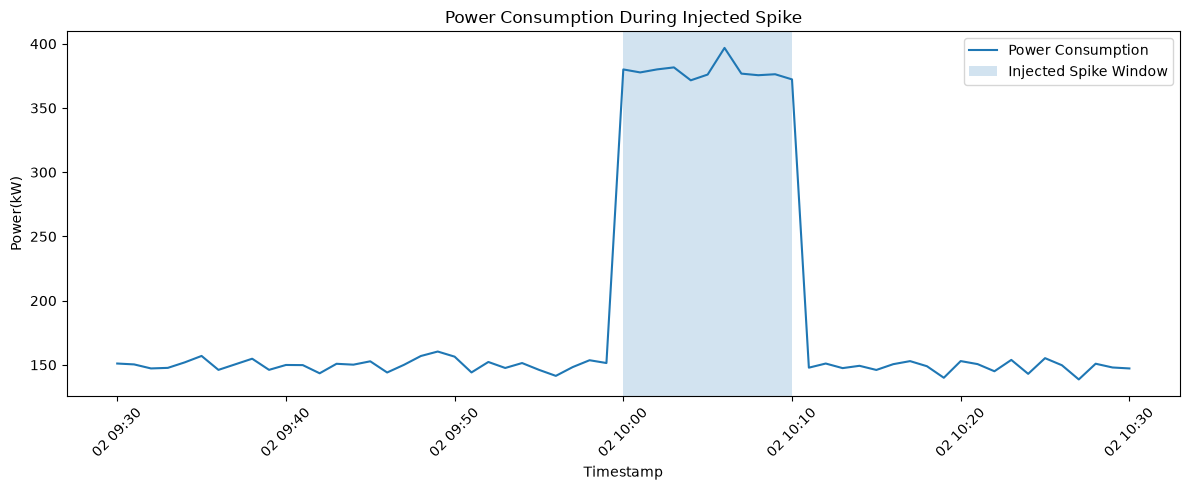

In [22]:
# Anomaly Visualization
# Visualizations help identify unusual patterns in industrial sensor readings and make the injected anomalies easier to interpret.

# Power Spike Visualization
# This graph highlights the sudden increase in power consumption between 10:00 and 10:10 on January 2, 2026.

import matplotlib.pyplot as plt

spike_plot_data = df[(df["timestamp"]>="2026-01-02 09:30:00") & (df["timestamp"]<="2026-01-02 10:30:00")]
plt.figure(figsize=(12, 5))
plt.plot(spike_plot_data["timestamp"],spike_plot_data["power_kw"],label="Power Consumption")
plt.axvspan(pd.Timestamp("2026-01-02 10:00:00"),pd.Timestamp("2026-01-02 10:10:00"),alpha=0.2,label="Injected Spike Window")

plt.title("Power Consumption During Injected Spike")
plt.xlabel("Timestamp")
plt.ylabel("Power(kW)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
# The graph shows a sudden increase in power consumption during the injected anomaly window (10:00–10:10). Power consumption rises from approximately 150 kW to around 380 kW and returns to its normal range after the event. This represents a spike anomaly where power consumption increases without a corresponding increase in flow rate.

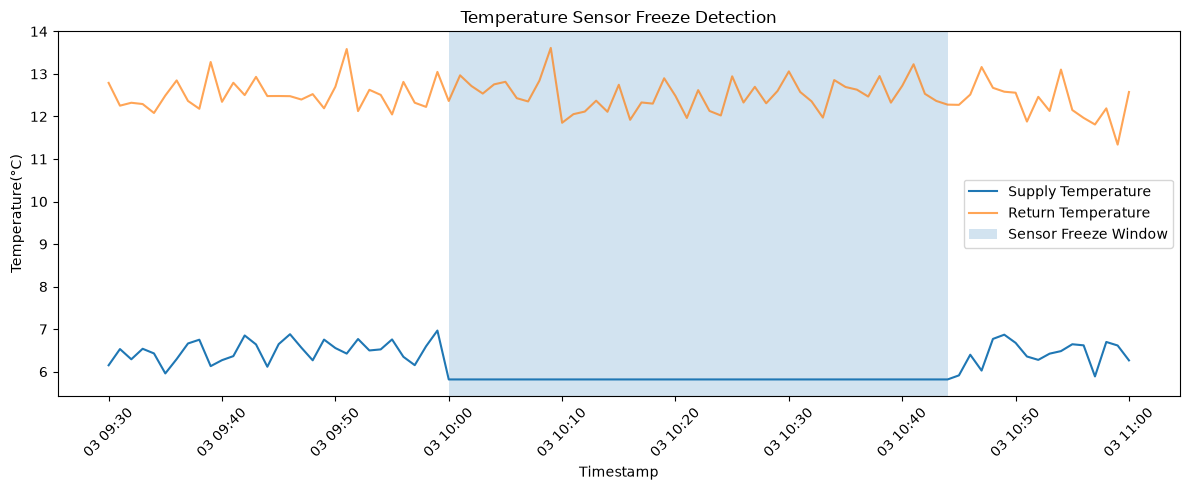

In [24]:
# Sensor Freeze Visualization
freeze_plot_data = df[(df["timestamp"]>="2026-01-03 09:30:00") & (df["timestamp"]<="2026-01-03 11:00:00")]
plt.figure(figsize=(12, 5))

plt.plot(freeze_plot_data["timestamp"],freeze_plot_data["supply_temp_c"], label="Supply Temperature")
plt.plot(freeze_plot_data["timestamp"],freeze_plot_data["return_temp_c"],label="Return Temperature",alpha=0.7)

plt.axvspan(pd.Timestamp("2026-01-03 10:00:00"),pd.Timestamp("2026-01-03 10:44:00"),alpha=0.2,label="Sensor Freeze Window")

plt.title("Temperature Sensor Freeze Detection")
plt.xlabel("Timestamp")
plt.ylabel("Temperature(°C)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# The supply temperature sensor remains constant at approximately 5.82°C for 45 consecutive minutes, while the return temperature continues to fluctuate. This indicates a sensor freeze anomaly, where the sensor stops reporting changing measurements despite variations in the operating environment.

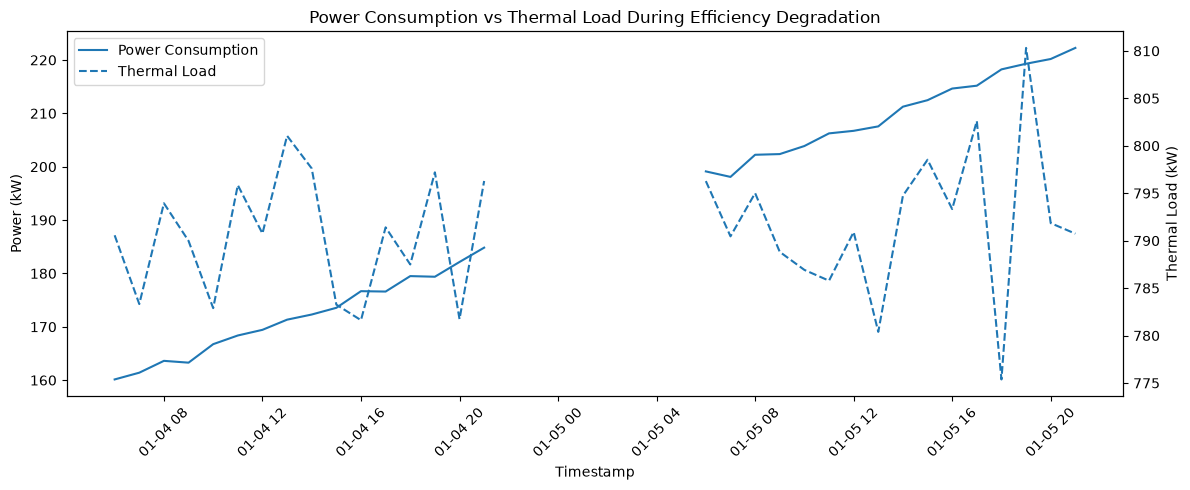

In [26]:
# Degraded Efficiency Visualization
degradation_plot_data = df[(df["timestamp"]>="2026-01-04 06:00:00") & (df["timestamp"]<="2026-01-05 21:59:00") & (df["status"]=="RUNNING")]

hourly_data = (degradation_plot_data.set_index("timestamp").resample("1h").agg({"power_kw":"mean","Thermal_Load_kW": "mean"}))
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(hourly_data.index,hourly_data["power_kw"],label="Power Consumption")
ax1.set_xlabel("Timestamp")
ax1.set_ylabel("Power (kW)")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(hourly_data.index,hourly_data["Thermal_Load_kW"],label="Thermal Load",linestyle="--")
ax2.set_ylabel("Thermal Load (kW)")

plt.title("Power Consumption vs Thermal Load During Efficiency Degradation")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()

In [27]:
print("Dataset shape:", df.shape)

print("\nPower consumption summary:")
display(df["power_kw"].describe().round(2))

print("\nPower during spike window:")
spike_check = df[(df["timestamp"]>="2026-01-02 10:00:00") & (df["timestamp"]<="2026-01-02 10:10:00")]

display(spike_check[["timestamp","power_kw","flow_rate_gpm"]].round({"power_kw":2,"flow_rate_gpm":2}))

print("\nMaximum power consumption:",round(df["power_kw"].max(), 2),"kW")

Dataset shape: (10080, 10)

Power consumption summary:


count    10080.00
mean       111.51
std         74.63
min          0.72
25%         22.94
50%        148.18
75%        155.84
max        396.79
Name: power_kw, dtype: float64


Power during spike window:


,timestamp,power_kw,flow_rate_gpm
2040,2026-01-02 10:00:00,380.04,484.67
2041,2026-01-02 10:01:00,377.70,484.42
2042,2026-01-02 10:02:00,380.06,483.34
2043,2026-01-02 10:03:00,381.62,513.84
2044,2026-01-02 10:04:00,371.57,508.83
2045,2026-01-02 10:05:00,376.04,496.51
2046,2026-01-02 10:06:00,396.79,540.61
2047,2026-01-02 10:07:00,376.78,499.75
2048,2026-01-02 10:08:00,375.53,500.90
2049,2026-01-02 10:09:00,376.29,489.72



Maximum power consumption: 396.79 kW


# Anomaly Detection Using Isolation Forest

In [28]:
# Isolation Forest is an unsupervised machine learning algorithm used to identify unusual patterns in industrial sensor data. It isolates abnormal observations based on their feature patterns.
# The model uses engineered sensor features to identify potential equipment anomalies.

In [29]:
# Model Feature Preparation
# The dataset is filtered to include only RUNNING records so that normal OFF and STANDBY operating conditions are not incorrectly classified as anomalies.
# A 30-minute rolling standard deviation is also calculated for supply temperature to help identify sensor-freeze behaviour.

# Select records when the equipment is running.
model_df = df[df["status"]=="RUNNING"].copy()

# Calculate 30-minute rolling temperature variation.
model_df["supply_temp_rolling_std"] = (model_df["supply_temp_c"].rolling(window=30, min_periods=30).std())

# Select features for Isolation Forest.
feature_columns = ["power_kw","flow_rate_gpm","supply_temp_c","return_temp_c","ambient_temp_c","Delta_T","Thermal_Load_kW","SEC","supply_temp_rolling_std"]

# Remove rows with missing feature values.
model_df = model_df.dropna(subset=feature_columns)

X = model_df[feature_columns]

print("Model dataset shape:", X.shape)
print("\nSelected features:")
print(X.columns.tolist())

print("\nMissing values:")
print(X.isnull().sum())

Model dataset shape: (6691, 9)

Selected features:
['power_kw', 'flow_rate_gpm', 'supply_temp_c', 'return_temp_c', 'ambient_temp_c', 'Delta_T', 'Thermal_Load_kW', 'SEC', 'supply_temp_rolling_std']

Missing values:
power_kw                   0
flow_rate_gpm              0
supply_temp_c              0
return_temp_c              0
ambient_temp_c             0
Delta_T                    0
Thermal_Load_kW            0
SEC                        0
supply_temp_rolling_std    0
dtype: int64


In [30]:
from sklearn.ensemble import IsolationForest

# Initialize the Isolation Forest model
isolation_model = IsolationForest(n_estimators=200,contamination=0.03,random_state=42,n_jobs=-1)
isolation_model.fit(X)
model_predictions = isolation_model.predict(X)

# Count predicted observations
unique, counts = np.unique(model_predictions, return_counts=True)

print("Isolation Forest training completed.")
print("\nPrediction summary:")

for label, count in zip(unique, counts):
    name = "Normal" if label == 1 else "Anomaly"
    print(f"{name}: {count}")

# 1 = Normal observation.
# -1 = Anomalous observation.   

Isolation Forest training completed.

Prediction summary:
Anomaly: 201
Normal: 6490


In [31]:
# Anomaly Score Calculation.
# Obtaining anomaly scores from Isolation Forest.
raw_scores = isolation_model.decision_function(X)

anomaly_scores = ((raw_scores.max()-raw_scores) / (raw_scores.max()-raw_scores.min()))

model_df["anomaly_score"]=anomaly_scores
model_df["model_prediction"]=model_predictions

print("Anomaly score calculation completed.")

print("\nAnomaly score summary:")
display(model_df["anomaly_score"].describe().round(4))

print("\nMinimum score:",round(model_df["anomaly_score"].min(),4))
print("Maximum score:",round(model_df["anomaly_score"].max(),4))

Anomaly score calculation completed.

Anomaly score summary:


count    6691.0000
mean        0.2526
std         0.1610
min         0.0000
25%         0.1292
50%         0.2181
75%         0.3443
max         1.0000
Name: anomaly_score, dtype: float64


Minimum score: 0.0
Maximum score: 1.0


In [32]:
# Anomaly Severity Classification
# Anomaly scores are converted into three severity levels:

# NORMAL: Score below 0.50
# WARNING: Score from 0.50 to below 0.75
# CRITICAL: Score equal to or above 0.75

# These thresholds are initial configuration values and require validation against known anomaly events.

In [33]:
# Assigning severity labels based on anomaly scores
model_df["severity"] = np.select([model_df["anomaly_score"]>=0.75,model_df["anomaly_score"]>= 0.50],["CRITICAL","WARNING"],default="NORMAL")
print("Anomaly severity distribution:")

severity_summary = (model_df["severity"].value_counts().reindex(["NORMAL","WARNING","CRITICAL"],fill_value=0))
display(severity_summary)

print("\nSample anomaly records:")
display(model_df.loc[model_df["severity"]!="NORMAL",["timestamp","power_kw","SEC","anomaly_score","severity"]].head(10).round({"power_kw":2,"SEC":3,"anomaly_score":4}))

Anomaly severity distribution:


severity
NORMAL      6120
WARNING      513
CRITICAL      58
Name: count, dtype: int64


Sample anomaly records:


,timestamp,power_kw,SEC,anomaly_score,severity
406,2026-01-01 06:46:00,150.57,0.212,0.5206,WARNING
450,2026-01-01 07:30:00,155.60,0.160,0.5430,WARNING
525,2026-01-01 08:45:00,154.32,0.242,0.5439,WARNING
526,2026-01-01 08:46:00,154.87,0.165,0.5110,WARNING
598,2026-01-01 09:58:00,154.82,0.235,0.5909,WARNING
616,2026-01-01 10:16:00,152.66,0.158,0.5795,WARNING
630,2026-01-01 10:30:00,150.90,0.153,0.6426,WARNING
637,2026-01-01 10:37:00,152.29,0.159,0.6512,WARNING
667,2026-01-01 11:07:00,143.28,0.145,0.6369,WARNING
678,2026-01-01 11:18:00,145.23,0.196,0.5287,WARNING


In [34]:
# Validation of Injected Anomalies
# The model predictions and anomaly scores are examined during the three injected anomaly periods to evaluate whether Isolation Forest identifies unusual equipment behaviour.
anomaly_windows = {
    "Power Spike": (
        "2026-01-02 10:00:00",
        "2026-01-02 10:10:00"
    ),
    "Sensor Freeze": (
        "2026-01-03 10:00:00",
        "2026-01-03 10:44:00"
    ),
    "Degraded Efficiency": (
        "2026-01-04 06:00:00",
        "2026-01-05 21:59:00"
    )
}
for anomaly_name, (start, end) in anomaly_windows.items():

    event_data = model_df[
        (model_df["timestamp"] >= start) &
        (model_df["timestamp"] <= end)
    ]
    print(f"\n{anomaly_name}")
    print("-" * 40)
    print("Records:", len(event_data))
    print("Mean anomaly score:", round(event_data["anomaly_score"].mean(), 4))
    print("Maximum anomaly score:", round(event_data["anomaly_score"].max(), 4))
    print("Isolation Forest anomalies:", (event_data["model_prediction"] == -1).sum())
    print("CRITICAL records:", (event_data["severity"] == "CRITICAL").sum())
    print("WARNING records:", (event_data["severity"] == "WARNING").sum())


Power Spike
----------------------------------------
Records: 11
Mean anomaly score: 0.7858
Maximum anomaly score: 0.8618
Isolation Forest anomalies: 11
CRITICAL records: 9
WARNING records: 2

Sensor Freeze
----------------------------------------
Records: 45
Mean anomaly score: 0.5008
Maximum anomaly score: 0.8967
Isolation Forest anomalies: 8
CRITICAL records: 4
WARNING records: 18

Degraded Efficiency
----------------------------------------
Records: 1920
Mean anomaly score: 0.3571
Maximum anomaly score: 1.0
Isolation Forest anomalies: 125
CRITICAL records: 38
WARNING records: 313


In [35]:
# Isolation Forest detected all power spike records but only some sensor freeze and degraded efficiency records. This shows that combining machine learning with diagnostic rules can improve anomaly detection.

In [36]:
# Rule-Based Sensor Freeze Detection
# Identify consecutive unchanged supply temperature readings.
model_df["temperature_unchanged"] = (model_df["supply_temp_c"].diff().abs()<0.000001)

# Checking whether the temperature remains unchanged for 30 readings.
model_df["sensor_freeze"] = (model_df["temperature_unchanged"].rolling(window=30, min_periods=30).sum()>=30)
print("Sensor freeze records detected:",model_df["sensor_freeze"].sum())

freeze_results = model_df[model_df["sensor_freeze"]][["timestamp", "supply_temp_c", "sensor_freeze"]]
display(freeze_results.head(10))

Sensor freeze records detected: 15


,timestamp,supply_temp_c,sensor_freeze
3510,2026-01-03 10:30:00,5.817645,True
3511,2026-01-03 10:31:00,5.817645,True
3512,2026-01-03 10:32:00,5.817645,True
3513,2026-01-03 10:33:00,5.817645,True
3514,2026-01-03 10:34:00,5.817645,True
3515,2026-01-03 10:35:00,5.817645,True
3516,2026-01-03 10:36:00,5.817645,True
3517,2026-01-03 10:37:00,5.817645,True
3518,2026-01-03 10:38:00,5.817645,True
3519,2026-01-03 10:39:00,5.817645,True


In [37]:
# Check consecutive unchanged temperature readings
unchanged = ((model_df["supply_temp_c"].diff().abs() < 0.000001) & (model_df["timestamp"].diff() == pd.Timedelta(minutes=1)))

# Group consecutive readings and size of each.
group_id = (~unchanged).cumsum()
group_size = group_id.map(group_id.value_counts())

# Flag the entire group if it contains at least 30 records
model_df["sensor_freeze"] = group_size >= 30

print("Sensor freeze records detected:",model_df["sensor_freeze"].sum())
display(model_df.loc[ model_df["sensor_freeze"],["timestamp","supply_temp_c","sensor_freeze"]].head(10))

Sensor freeze records detected: 45


,timestamp,supply_temp_c,sensor_freeze
3480,2026-01-03 10:00:00,5.817645,True
3481,2026-01-03 10:01:00,5.817645,True
3482,2026-01-03 10:02:00,5.817645,True
3483,2026-01-03 10:03:00,5.817645,True
3484,2026-01-03 10:04:00,5.817645,True
3485,2026-01-03 10:05:00,5.817645,True
3486,2026-01-03 10:06:00,5.817645,True
3487,2026-01-03 10:07:00,5.817645,True
3488,2026-01-03 10:08:00,5.817645,True
3489,2026-01-03 10:09:00,5.817645,True


In [38]:
# The rule-based method successfully detected all 45 records of the injected sensor freeze, demonstrating improved detection compared with Isolation Forest alone.

In [39]:
# Rule-Based Degraded Efficiency Detection
# Calculate 6-hour operating averages
efficiency_data = (model_df.set_index("timestamp").resample("6h").agg({"power_kw": "mean","Thermal_Load_kW": "mean"}).dropna())

# Comparing 
power_change = efficiency_data["power_kw"].pct_change()
thermal_change = efficiency_data["Thermal_Load_kW"].pct_change()

# Identifying potential efficiency degradation
efficiency_data["degraded_efficiency"] = ((power_change >= 0.15) & (thermal_change.abs() <= 0.05))

print("Potential degraded efficiency periods:",efficiency_data["degraded_efficiency"].sum())
display(efficiency_data[efficiency_data["degraded_efficiency"]].round(2))

Potential degraded efficiency periods: 0


,power_kw,Thermal_Load_kW,degraded_efficiency
timestamp,,,


In [40]:
# Calculate percentage changes between operating windows
efficiency_check = efficiency_data.copy()
efficiency_check["power_change_pct"] = (efficiency_check["power_kw"].pct_change()*100)
efficiency_check["thermal_change_pct"] = (efficiency_check["Thermal_Load_kW"].pct_change()*100)
display(efficiency_check.round(2))

,power_kw,Thermal_Load_kW,degraded_efficiency,power_change_pct,thermal_change_pct
timestamp,,,,,
2026-01-01 06:00:00,150.05,792.92,False,NaN,NaN
2026-01-01 12:00:00,150.32,793.64,False,0.18,0.09
2026-01-01 18:00:00,149.13,787.52,False,-0.79,-0.77
2026-01-02 06:00:00,156.56,789.01,False,4.98,0.19
2026-01-02 12:00:00,150.08,784.26,False,-4.13,-0.60
2026-01-02 18:00:00,150.03,796.89,False,-0.04,1.61
2026-01-03 06:00:00,149.97,802.38,False,-0.04,0.69
2026-01-03 12:00:00,150.54,794.25,False,0.38,-1.01
2026-01-03 18:00:00,149.42,791.12,False,-0.74,-0.39


In [41]:
# Establish normal operating baseline (January 1–3)
baseline = efficiency_data[efficiency_data.index<"2026-01-04"]
baseline_power = baseline["power_kw"].median()
baseline_thermal = baseline["Thermal_Load_kW"].median()

# Calculate changes relative to normal baseline
efficiency_data["power_increase_pct"] = ((efficiency_data["power_kw"] - baseline_power)/baseline_power*100)
efficiency_data["thermal_change_pct"] = ((efficiency_data["Thermal_Load_kW"] - baseline_thermal)/ baseline_thermal*100)

# Detect degraded efficiency
efficiency_data["degraded_efficiency"] = ((efficiency_data["power_increase_pct"]>=15) & (efficiency_data["thermal_change_pct"].abs()<=5))
print("Normal baseline power:", round(baseline_power,2),"kW")
print("Normal baseline thermal load:", round(baseline_thermal,2),"kW")
print("\nDegraded efficiency periods detected:",efficiency_data["degraded_efficiency"].sum())
display(efficiency_data[efficiency_data["degraded_efficiency"]].round(2))

Normal baseline power: 150.05 kW
Normal baseline thermal load: 792.92 kW

Degraded efficiency periods detected: 5


,power_kw,Thermal_Load_kW,degraded_efficiency,power_increase_pct,thermal_change_pct
timestamp,,,,,
2026-01-04 12:00:00,173.32,790.95,True,15.51,-0.25
2026-01-04 18:00:00,181.46,790.68,True,20.94,-0.28
2026-01-05 06:00:00,201.99,790.54,True,34.61,-0.30
2026-01-05 12:00:00,211.30,793.42,True,40.82,0.06
2026-01-05 18:00:00,219.99,792.07,True,46.61,-0.11


In [42]:
# The rule-based method detected 5 degraded efficiency periods. Power consumption increased by up to 46.61%, while thermal load remained stable. This indicates reduced equipment efficiency.

In [43]:
# Hybrid Anomaly Detection System.
# Maping degraded efficiency periods to the minute-level dataset
model_df["degraded_efficiency"] = (model_df["timestamp"].dt.floor("6h").map(efficiency_data["degraded_efficiency"]).fillna(False))

# Combining all three detection methods.
model_df["hybrid_anomaly"] = ((model_df["model_prediction"] == -1) | model_df["sensor_freeze"] | model_df["degraded_efficiency"])

# Assigning final severity labels.
model_df["final_severity"] = np.select([model_df["sensor_freeze"] | model_df["degraded_efficiency"],model_df["model_prediction"]==-1],["CRITICAL","WARNING"],default="NORMAL")

print("Hybrid anomaly detection completed.")
print("\nFinal severity distribution:")
display(model_df["final_severity"].value_counts().reindex(["NORMAL", "WARNING", "CRITICAL"], fill_value=0))
print("\nTotal hybrid anomaly records:", model_df["hybrid_anomaly"].sum())

Hybrid anomaly detection completed.

Final severity distribution:


final_severity
NORMAL      5013
WARNING       73
CRITICAL    1605
Name: count, dtype: int64


Total hybrid anomaly records: 1678


In [44]:
# The hybrid system combines Isolation Forest with rule-based detection to identify unusual equipment behaviour. It classified 5,013 records as NORMAL,73 as WARNING,and 1,605 as CRITICAL.

In [45]:
# Validating the hybrid system.
for anomaly_name, (start, end) in anomaly_windows.items():
    event_data = model_df[
        (model_df["timestamp"] >= start) & (model_df["timestamp"] <= end)]

    print(f"\n{anomaly_name}")
    print("-" * 35)
    print("Total records:", len(event_data))
    print("Detected anomalies:", event_data["hybrid_anomaly"].sum())
    print("NORMAL:",(event_data["final_severity"]=="NORMAL").sum())
    print("WARNING:",(event_data["final_severity"]=="WARNING").sum())
    print("CRITICAL:",(event_data["final_severity"]=="CRITICAL").sum())


Power Spike
-----------------------------------
Total records: 11
Detected anomalies: 11
NORMAL: 0
CRITICAL: 0

Sensor Freeze
-----------------------------------
Total records: 45
Detected anomalies: 45
NORMAL: 0
CRITICAL: 45

Degraded Efficiency
-----------------------------------
Total records: 1920
Detected anomalies: 1565
NORMAL: 355
CRITICAL: 1560


In [46]:
# The hybrid system detected all power spike and sensor freeze records, along with 1,565 degraded efficiency records.Combining machine learning with diagnostic rules improved anomaly detection across the three injected events.

In [47]:
# The trained model is saved and ready for the FastAPI application to use for anomaly detection.

In [48]:
from pathlib import Path

files = [
    "src/__init__.py",
    "src/api/__init__.py",
    "src/core/__init__.py",
    "src/models/__init__.py",
    "src/services/__init__.py",
    "src/api/main.py",
    "src/models/schemas.py",
    "src/services/diagnosis.py"
]

for file in files:
    path = Path(file)
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        path.touch()

print("API project files created.")

API project files created.


In [49]:
from pathlib import Path
model_path = Path(r"C:\Users\AKARSH.K\Desktop\EquipmentIQ\artifacts\equipmentiq_model.joblib")
print("Model exists:", model_path.exists())

Model exists: True


In [50]:
variables = ["df","isolation_model","feature_columns","raw_scores","baseline_power","baseline_thermal"]
for variable in variables:
    print(f"{variable}: {variable in globals()}")

df: True
isolation_model: True
feature_columns: True
raw_scores: True
baseline_power: True
baseline_thermal: True


In [51]:
import joblib
from pathlib import Path

artifacts_dir = Path(r"C:\Users\AKARSH.K\Desktop\EquipmentIQ\artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

model_artifact = {
    "model": isolation_model,
    "feature_columns": feature_columns,
    "score_min": float(raw_scores.min()),
    "score_max": float(raw_scores.max()),
    "baseline_power_kw": float(baseline_power),
    "baseline_thermal_load_kw": float(baseline_thermal),
    "contamination": 0.03,
    "score_thresholds": {
        "warning": 0.50,
        "critical": 0.75
    }
}

model_path = artifacts_dir / "equipmentiq_model.joblib"
joblib.dump(model_artifact, model_path)

print("Model saved successfully:", model_path)
print("File exists:", model_path.exists())

Model saved successfully: C:\Users\AKARSH.K\Desktop\EquipmentIQ\artifacts\equipmentiq_model.joblib
File exists: True


In [52]:
# EquipmentIQ_API_Dependencies
import sys

!{sys.executable} -m pip install fastapi "uvicorn[standard]"

In [53]:
# EquipmentIQ_Python_Environment_Check
import sys
from pathlib import Path

print("Python executable:", sys.executable)
print("Project venv Python:", Path(r"C:\Users\AKARSH.K\Desktop\EquipmentIQ\venv\Scripts\python.exe").exists())

Python executable: C:\Users\AKARSH.K\Desktop\EquipmentIQ\venv\Scripts\python.exe
Project venv Python: True


In [54]:
# EquipmentIQ_API_Server_Startup
import subprocess
import sys
from pathlib import Path

project_dir = Path(r"C:\Users\AKARSH.K\Desktop\EquipmentIQ")

server_process = subprocess.Popen([sys.executable,"-m","uvicorn","src.api.main:app","--host","127.0.0.1","--port","8000"],cwd=project_dir)

print("EquipmentIQ API started.")
print("Process ID:", server_process.pid)
print("API URL: http://127.0.0.1:8000")
print("Swagger documentation: http://127.0.0.1:8000/docs")

EquipmentIQ API started.
Process ID: 11924
API URL: http://127.0.0.1:8000
Swagger documentation: http://127.0.0.1:8000/docs


In [55]:
# EquipmentIQ_API_Health_Check
import requests
response = requests.get("http://127.0.0.1:8000/health")
print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 200
Response: {'status': 'healthy', 'service': 'EquipmentIQ'}


In [56]:
# EquipmentIQ_Single_Reading_Diagnosis_Test
import requests

url = "http://127.0.0.1:8000/api/v1/diagnose"

sample_reading = {"timestamp": "2026-01-02T10:05:00","power_kw": 375,"flow_rate_gpm": 50,"supply_temp_c": 7,"return_temp_c": 12,"ambient_temp_c": 25,"status": "RUNNING"}

response = requests.post(url, json=sample_reading)

print("Status Code:", response.status_code)
print("Diagnosis:", response.json())

Status Code: 200
Diagnosis: {'timestamp': '2026-01-02T10:05:00', 'anomaly_score': 1.0, 'severity': 'CRITICAL', 'diagnosis': 'Unusual equipment behaviour detected.'}


In [57]:
# EquipmentIQ_Batch_Audit_Test
import requests

url = "http://127.0.0.1:8000/api/v1/batch-audit"

batch_data = {
    "readings": [
        {
            "timestamp": "2026-01-02T10:05:00",
            "power_kw": 375,
            "flow_rate_gpm": 50,
            "supply_temp_c": 7,
            "return_temp_c": 12,
            "ambient_temp_c": 25,
            "status": "RUNNING"
        },
        {
            "timestamp": "2026-01-02T11:00:00",
            "power_kw": 150,
            "flow_rate_gpm": 50,
            "supply_temp_c": 7,
            "return_temp_c": 12,
            "ambient_temp_c": 25,
            "status": "RUNNING"
        }
    ]
}

response = requests.post(url, json=batch_data)

print("Status Code:", response.status_code)
print("Batch Audit:", response.json())

Status Code: 200
Batch Audit: {'total_records': 2, 'anomaly_count': 2, 'results': [{'timestamp': '2026-01-02T10:05:00', 'anomaly_score': 1.0, 'severity': 'CRITICAL', 'diagnosis': 'Unusual equipment behaviour detected.'}, {'timestamp': '2026-01-02T11:00:00', 'anomaly_score': 1.0, 'severity': 'CRITICAL', 'diagnosis': 'Unusual equipment behaviour detected.'}]}


In [58]:
# EquipmentIQ_API_Metrics_Test
import requests

response = requests.get("http://127.0.0.1:8000/metrics")
print("Status Code:", response.status_code)
print("Metrics:", response.json())

Status Code: 200
Metrics: {'service': 'EquipmentIQ', 'status': 'operational', 'available_endpoints': 4}


In [59]:
# EquipmentIQ_Actual_Dataset_Diagnosis_Test
import requests

# Selecting one actual RUNNING record from your dataset.
sample = df[df["status"] == "RUNNING"].iloc[100]

reading = {
    "timestamp": sample["timestamp"].isoformat(),
    "power_kw": float(sample["power_kw"]),
    "flow_rate_gpm": float(sample["flow_rate_gpm"]),
    "supply_temp_c": float(sample["supply_temp_c"]),
    "return_temp_c": float(sample["return_temp_c"]),
    "ambient_temp_c": float(sample["ambient_temp_c"]),
    "status": sample["status"]
}

response = requests.post("http://127.0.0.1:8000/api/v1/diagnose",json=reading)

print("Input reading:", reading)
print("Status Code:", response.status_code)
print("Diagnosis:", response.json())

Input reading: {'timestamp': '2026-01-01T07:40:00', 'power_kw': 151.2231132055714, 'flow_rate_gpm': 495.9045672673819, 'supply_temp_c': 6.609327773358746, 'return_temp_c': 12.064848418576698, 'ambient_temp_c': 28.19223028613886, 'status': 'RUNNING'}
Status Code: 200
Diagnosis: {'timestamp': '2026-01-01T07:40:00', 'anomaly_score': 0.3438039922536468, 'severity': 'NORMAL', 'diagnosis': 'Equipment is operating within expected limits.'}


In [60]:
# EquipmentIQ_Power_Spike_Diagnosis_Test
import requests

# Selecting an actual injected power-spike record
spike_sample = df[(df["timestamp"] == "2026-01-02 10:05:00")].iloc[0]

spike_reading = {
    "timestamp": spike_sample["timestamp"].isoformat(),
    "power_kw": float(spike_sample["power_kw"]),
    "flow_rate_gpm": float(spike_sample["flow_rate_gpm"]),
    "supply_temp_c": float(spike_sample["supply_temp_c"]),
    "return_temp_c": float(spike_sample["return_temp_c"]),
    "ambient_temp_c": float(spike_sample["ambient_temp_c"]),
    "status": spike_sample["status"]
}

response = requests.post("http://127.0.0.1:8000/api/v1/diagnose",json=spike_reading)

print("Status Code:", response.status_code)
print("Power:", spike_reading["power_kw"])
print("Diagnosis:", response.json())

Status Code: 200
Power: 376.0361320177452
Diagnosis: {'timestamp': '2026-01-02T10:05:00', 'anomaly_score': 0.9373458883240814, 'severity': 'CRITICAL', 'diagnosis': 'Unusual equipment behaviour detected.'}


In [61]:
# EquipmentIQ_Sensor_Freeze_Diagnosis_Test
import requests

freeze_sample = df[(df["timestamp"] == "2026-01-03 10:20:00")].iloc[0]
freeze_reading = {
    "timestamp": freeze_sample["timestamp"].isoformat(),
    "power_kw": float(freeze_sample["power_kw"]),
    "flow_rate_gpm": float(freeze_sample["flow_rate_gpm"]),
    "supply_temp_c": float(freeze_sample["supply_temp_c"]),
    "return_temp_c": float(freeze_sample["return_temp_c"]),
    "ambient_temp_c": float(freeze_sample["ambient_temp_c"]),
    "status": freeze_sample["status"]
}

response = requests.post("http://127.0.0.1:8000/api/v1/diagnose",json=freeze_reading)

print("Status Code:", response.status_code)
print("Diagnosis:", response.json())

Status Code: 200
Diagnosis: {'timestamp': '2026-01-03T10:20:00', 'anomaly_score': 0.546232752464426, 'severity': 'WARNING', 'diagnosis': 'Potential equipment anomaly detected.'}


In [62]:
# EquipmentIQ_API_Restart
# Stop the previous API server
try:
    server_process.terminate()
    server_process.wait(timeout=10)
    print("Previous API server stopped.")
except Exception as error:
    print("Previous server status:", error)

# Start the updated API server
import subprocess
import sys
from pathlib import Path

project_dir = Path(r"C:\Users\AKARSH.K\Desktop\EquipmentIQ")

server_process = subprocess.Popen([sys.executable,"-m","uvicorn","src.api.main:app","--host","127.0.0.1","--port","8000"],cwd=project_dir)

print("Updated EquipmentIQ API started.")
print("Process ID:", server_process.pid)
print("API documentation: http://127.0.0.1:8000/docs")

Previous API server stopped.
Updated EquipmentIQ API started.
Process ID: 20712
API documentation: http://127.0.0.1:8000/docs


In [63]:
# EquipmentIQ_Sensor_Freeze_Batch_Test
import requests

# Selecting the complete injected sensor-freeze period.
freeze_data = df[(df["timestamp"]>="2026-01-03 10:00:00") & (df["timestamp"]<="2026-01-03 10:44:00") &(df["status"]=="RUNNING")].copy()
readings = []
for _, sample in freeze_data.iterrows():
    readings.append({
        "timestamp": sample["timestamp"].isoformat(),
        "power_kw": float(sample["power_kw"]),
        "flow_rate_gpm": float(sample["flow_rate_gpm"]),
        "supply_temp_c": float(sample["supply_temp_c"]),
        "return_temp_c": float(sample["return_temp_c"]),
        "ambient_temp_c": float(sample["ambient_temp_c"]),
        "status": sample["status"]
    })

response = requests.post("http://127.0.0.1:8000/api/v1/batch-audit",json={"readings":readings})
result = response.json()

print("Status Code:",response.status_code)
print("Total Records:",result.get("total_records"))

critical_count = sum(item["severity"]=="CRITICAL"for item in result.get("results",[]))

print("Critical Records:", critical_count)
print("First Diagnosis:", result["results"][0])

Status Code: 200
Total Records: 45
Critical Records: 45
First Diagnosis: {'timestamp': '2026-01-03T10:00:00', 'anomaly_score': 0.75, 'severity': 'CRITICAL', 'diagnosis': 'CRITICAL: supply_temp_c sensor remained unchanged for more than 30 minutes.'}


In [64]:
# EquipmentIQ_Degraded_Efficiency_Batch_Test
import requests

# Selecting the injected degraded-efficiency period
degraded_data = df[(df["timestamp"]>="2026-01-04 00:00:00") & (df["timestamp"]<"2026-01-06 00:00:00") & (df["status"]=="RUNNING")].copy()

readings = []

for _, sample in degraded_data.iterrows():
    readings.append({
        "timestamp": sample["timestamp"].isoformat(),
        "power_kw": float(sample["power_kw"]),
        "flow_rate_gpm": float(sample["flow_rate_gpm"]),
        "supply_temp_c": float(sample["supply_temp_c"]),
        "return_temp_c": float(sample["return_temp_c"]),
        "ambient_temp_c": float(sample["ambient_temp_c"]),
        "status": sample["status"]
    })

response = requests.post("http://127.0.0.1:8000/api/v1/batch-audit",json={"readings":readings})
result = response.json()

critical_count = sum(item["severity"] == "CRITICAL" for item in result.get("results",[]))

warning_count = sum(item["severity"] =="WARNING" for item in result.get("results", []))

print("Status Code:", response.status_code)
print("Total Records:", result.get("total_records"))
print("Critical Records:", critical_count)
print("Warning Records:", warning_count)
print("First Diagnosis:", result["results"][0])

Status Code: 200
Total Records: 1920
Critical Records: 1568
Warning Records: 88
First Diagnosis: {'timestamp': '2026-01-04T06:00:00', 'anomaly_score': 0.4180329733241315, 'severity': 'NORMAL', 'diagnosis': 'Equipment is operating within expected limits.'}


In [65]:
# EquipmentIQ_API_Restart_After_Efficiency_Update
# Stop the previous API server.
try:
    server_process.terminate()
    server_process.wait(timeout=10)
    print("Previous API server stopped.")
except Exception as error:
    print("Previous server status:", error)

# Start the updated API.
import subprocess
import sys
from pathlib import Path

project_dir = Path(r"C:\Users\AKARSH.K\Desktop\EquipmentIQ")

server_process = subprocess.Popen([sys.executable,"-m", "uvicorn","src.api.main:app","--host", "127.0.0.1","--port", "8000"],cwd=project_dir)

print("Updated EquipmentIQ API started.")
print("Process ID:", server_process.pid)

Previous API server stopped.
Updated EquipmentIQ API started.
Process ID: 17800


In [69]:
# EquipmentIQ_Hybrid_Anomaly_Validation
import requests

# Use all RUNNING records so the API has baseline and degraded periods
test_data = df[df["status"] == "RUNNING"].copy()

readings = []

for _, sample in test_data.iterrows():
    readings.append({
        "timestamp": sample["timestamp"].isoformat(),
        "power_kw": float(sample["power_kw"]),
        "flow_rate_gpm": float(sample["flow_rate_gpm"]),
        "supply_temp_c": float(sample["supply_temp_c"]),
        "return_temp_c": float(sample["return_temp_c"]),
        "ambient_temp_c": float(sample["ambient_temp_c"]),
        "status": sample["status"]
    })

response = requests.post("http://127.0.0.1:8000/api/v1/batch-audit",json={"readings": readings},timeout=180)

print("Status Code:", response.status_code)

result = response.json()

print("Total Records:", result.get("total_records"))
print("Anomaly Count:", result.get("anomaly_count"))

# Counting diagnosis categories
from collections import Counter

diagnosis_counts = Counter(item["diagnosis"] for item in result["results"])

for diagnosis, count in diagnosis_counts.items():
    print(count, "records:", diagnosis)

Status Code: 200
Total Records: 6720
Anomaly Count: 2931
3789 records: Equipment is operating within expected limits.
1189 records: Potential equipment anomaly detected.
137 records: Unusual equipment behaviour detected.
45 records: CRITICAL: supply_temp_c sensor remained unchanged for more than 30 minutes.
1560 records: CRITICAL: Degraded efficiency detected. Power consumption increased while thermal output remained nearly constant.


In [70]:
from pathlib import Path

project_dir = Path(r"C:\Users\AKARSH.K\Desktop\EquipmentIQ")
tests_dir = project_dir / "tests"
tests_dir.mkdir(exist_ok=True)

test_code = r'''
from datetime import datetime, timedelta

from fastapi.testclient import TestClient
from src.api.main import app

client = TestClient(app)


def sample_reading(timestamp="2026-01-01T07:40:00"):
    return {
        "timestamp": timestamp,
        "power_kw": 151.2,
        "flow_rate_gpm": 495.9,
        "supply_temp_c": 6.6,
        "return_temp_c": 12.1,
        "ambient_temp_c": 28.2,
        "status": "RUNNING"
    }


def test_health():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json()["status"] == "healthy"


def test_diagnose():
    response = client.post(
        "/api/v1/diagnose",
        json=sample_reading()
    )
    assert response.status_code == 200

    result = response.json()
    assert 0 <= result["anomaly_score"] <= 1
    assert result["severity"] in ["NORMAL", "WARNING", "CRITICAL"]


def test_batch_audit():
    readings = [
        sample_reading("2026-01-01T07:40:00"),
        sample_reading("2026-01-01T07:41:00")
    ]

    response = client.post(
        "/api/v1/batch-audit",
        json={"readings": readings}
    )

    assert response.status_code == 200
    assert response.json()["total_records"] == 2
    assert len(response.json()["results"]) == 2


def test_empty_batch_rejected():
    response = client.post(
        "/api/v1/batch-audit",
        json={"readings": []}
    )
    assert response.status_code == 422


def test_sensor_freeze_detection():
    start = datetime(2026, 1, 3, 10, 0)

    readings = []
    for i in range(40):
        reading = sample_reading(
            (start + timedelta(minutes=i)).isoformat()
        )
        reading["supply_temp_c"] = 6.6
        readings.append(reading)

    response = client.post(
        "/api/v1/batch-audit",
        json={"readings": readings}
    )

    assert response.status_code == 200

    results = response.json()["results"]
    assert any(
        result["severity"] == "CRITICAL"
        and "supply_temp_c" in result["diagnosis"]
        for result in results
    )
'''

test_file = tests_dir / "test_api.py"
test_file.write_text(test_code, encoding="utf-8")

print("Test file created/updated:", test_file)

Test file created/updated: C:\Users\AKARSH.K\Desktop\EquipmentIQ\tests\test_api.py


In [71]:
import subprocess
import sys
from pathlib import Path

project_dir = Path(r"C:\Users\AKARSH.K\Desktop\EquipmentIQ")

result = subprocess.run([sys.executable, "-m", "pytest", "tests/test_api.py", "-v"],cwd=project_dir,capture_output=True,text=True)

print(result.stdout)
print(result.stderr)
print("Exit code:", result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.13.5, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\AKARSH.K\Desktop\EquipmentIQ\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\AKARSH.K\Desktop\EquipmentIQ
plugins: anyio-4.16.0, platformdirs-4.14.3, cov-7.1.0
collecting ... collected 0 items / 1 error

=================================== ERRORS ====================================
_____________________ ERROR collecting tests/test_api.py ______________________
ImportError while importing test module 'C:\Users\AKARSH.K\Desktop\EquipmentIQ\tests\test_api.py'.
Hint: make sure your test modules/packages have valid Python names.
Traceback:
..\..\AppData\Local\Programs\Python\Python313\Lib\importlib\__init__.py:88: in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
tests\test_api.py:5: in <module>
    from src.api.main import app
E

In [72]:
from pathlib import Path

project_dir = Path(r"C:\Users\AKARSH.K\Desktop\EquipmentIQ")
test_file = project_dir / "tests" / "test_api.py"

test_code = '''
from datetime import datetime, timedelta
from fastapi.testclient import TestClient
from src.api.main import app

client = TestClient(app)


def sample_reading(timestamp="2026-01-01T07:40:00"):
    return {
        "timestamp": timestamp,
        "power_kw": 151.2,
        "flow_rate_gpm": 495.9,
        "supply_temp_c": 6.6,
        "return_temp_c": 12.1,
        "ambient_temp_c": 28.2,
        "status": "RUNNING"
    }


def test_health():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json()["status"] == "healthy"


def test_diagnose():
    response = client.post("/api/v1/diagnose", json=sample_reading())
    assert response.status_code == 200
    result = response.json()
    assert 0 <= result["anomaly_score"] <= 1


def test_batch_audit():
    readings = [
        sample_reading("2026-01-01T07:40:00"),
        sample_reading("2026-01-01T07:41:00")
    ]
    response = client.post("/api/v1/batch-audit", json={"readings": readings})
    assert response.status_code == 200
    assert response.json()["total_records"] == 2


def test_empty_batch_rejected():
    response = client.post("/api/v1/batch-audit", json={"readings": []})
    assert response.status_code == 422


def test_sensor_freeze_detection():
    start = datetime(2026, 1, 3, 10, 0)
    readings = []

    for i in range(40):
        reading = sample_reading(
            (start + timedelta(minutes=i)).isoformat()
        )
        reading["supply_temp_c"] = 6.6
        readings.append(reading)

    response = client.post("/api/v1/batch-audit", json={"readings": readings})
    assert response.status_code == 200

    results = response.json()["results"]

    print("Freeze test results:")
    for result in results:
        print(result["timestamp"], result["severity"], result["diagnosis"])

    assert any(
        result["severity"] == "CRITICAL"
        and "supply_temp_c" in result["diagnosis"]
        for result in results
    )
'''

test_file.write_text(test_code, encoding="utf-8")

print("Saved successfully:", test_file)
print("File size:", test_file.stat().st_size, "bytes")
print(test_file.read_text(encoding="utf-8"))

Saved successfully: C:\Users\AKARSH.K\Desktop\EquipmentIQ\tests\test_api.py
File size: 2043 bytes

from datetime import datetime, timedelta
from fastapi.testclient import TestClient
from src.api.main import app

client = TestClient(app)


def sample_reading(timestamp="2026-01-01T07:40:00"):
    return {
        "timestamp": timestamp,
        "power_kw": 151.2,
        "flow_rate_gpm": 495.9,
        "supply_temp_c": 6.6,
        "return_temp_c": 12.1,
        "ambient_temp_c": 28.2,
        "status": "RUNNING"
    }


def test_health():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json()["status"] == "healthy"


def test_diagnose():
    response = client.post("/api/v1/diagnose", json=sample_reading())
    assert response.status_code == 200
    result = response.json()
    assert 0 <= result["anomaly_score"] <= 1


def test_batch_audit():
    readings = [
        sample_reading("2026-01-01T07:40:00"),
        sample_reading("2026-01-01

In [73]:
import subprocess
import sys
from pathlib import Path

project_dir = Path(r"C:\Users\AKARSH.K\Desktop\EquipmentIQ")

result = subprocess.run([sys.executable,"-m","pytest","tests/test_api.py","-v","-s"],cwd=project_dir,capture_output=True,text=True)

print(result.stdout)
print(result.stderr)
print("Exit code:", result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.13.5, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\AKARSH.K\Desktop\EquipmentIQ\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\AKARSH.K\Desktop\EquipmentIQ
plugins: anyio-4.16.0, platformdirs-4.14.3, cov-7.1.0
collecting ... collected 0 items / 1 error

=================================== ERRORS ====================================
_____________________ ERROR collecting tests/test_api.py ______________________
ImportError while importing test module 'C:\Users\AKARSH.K\Desktop\EquipmentIQ\tests\test_api.py'.
Hint: make sure your test modules/packages have valid Python names.
Traceback:
..\..\AppData\Local\Programs\Python\Python313\Lib\importlib\__init__.py:88: in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
tests\test_api.py:4: in <module>
    from src.api.main import app
E

In [74]:
result = subprocess.run([sys.executable, "-m", "pytest", "tests/test_api.py", "-v"],cwd=project_dir,capture_output=True,text=True)
print(result.stdout)
print(result.stderr)
print("Exit code:", result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.13.5, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\AKARSH.K\Desktop\EquipmentIQ\venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\AKARSH.K\Desktop\EquipmentIQ
plugins: anyio-4.16.0, platformdirs-4.14.3, cov-7.1.0
collecting ... collected 0 items / 1 error

=================================== ERRORS ====================================
_____________________ ERROR collecting tests/test_api.py ______________________
ImportError while importing test module 'C:\Users\AKARSH.K\Desktop\EquipmentIQ\tests\test_api.py'.
Hint: make sure your test modules/packages have valid Python names.
Traceback:
..\..\AppData\Local\Programs\Python\Python313\Lib\importlib\__init__.py:88: in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
tests\test_api.py:4: in <module>
    from src.api.main import app
E

In [75]:
result = subprocess.run([sys.executable, "-m", "pytest","tests/test_api.py","--cov=src","--cov-report=term-missing"],cwd=project_dir,capture_output=True,text=True)
print(result.stdout)
print(result.stderr)
print("Exit code:", result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.13.5, pytest-9.2.0, pluggy-1.7.0
rootdir: C:\Users\AKARSH.K\Desktop\EquipmentIQ
plugins: anyio-4.16.0, platformdirs-4.14.3, cov-7.1.0
collected 0 items / 1 error

=================================== ERRORS ====================================
_____________________ ERROR collecting tests/test_api.py ______________________
ImportError while importing test module 'C:\Users\AKARSH.K\Desktop\EquipmentIQ\tests\test_api.py'.
Hint: make sure your test modules/packages have valid Python names.
Traceback:
..\..\AppData\Local\Programs\Python\Python313\Lib\importlib\__init__.py:88: in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
tests\test_api.py:4: in <module>
    from src.api.main import app
E   ImportError: cannot import name 'app' from 'src.api.main' (C:\Users\AKARSH.K\Desktop\EquipmentIQ\src\

# 48-Hour Degraded Efficiency Detection – API Validation Test

In [77]:
import requests
import numpy as np
import pandas as pd

timestamps = pd.date_range(start="2026-01-04 00:00:00",periods=2880,freq="min")

readings = []

for i, timestamp in enumerate(timestamps):
    variation = 0.1 * np.sin(i / 20)

    supply = 6.0 + variation
    return_temp = supply + 6.0

    elapsed_hours = i / 60
    power = 150 * (1 + 0.50 * elapsed_hours / 48)

    readings.append({
        "timestamp": timestamp.isoformat(),
        "power_kw": float(power),
        "flow_rate_gpm": 500.0,
        "supply_temp_c": float(supply),
        "return_temp_c": float(return_temp),
        "ambient_temp_c": 28.0,
        "status": "RUNNING"
    })

response = requests.post("http://localhost:8000/api/v1/batch-audit",json={"readings": readings},timeout=120)

print("HTTP Status:", response.status_code)

result = response.json()

print("Total Records:", result["total_records"])
print("Anomaly Count:", result["anomaly_count"])

print("\nSeverity Summary:")
print(pd.Series([r["severity"] for r in result["results"]]).value_counts())

print("\nFirst Diagnosis:", result["results"][0]["diagnosis"])
print("Last Diagnosis:", result["results"][-1]["diagnosis"])

HTTP Status: 200
Total Records: 2880
Anomaly Count: 2335

Severity Summary:
CRITICAL    2160
NORMAL       545
WARNING      175
Name: count, dtype: int64

First Diagnosis: Equipment is operating within expected limits.
Last Diagnosis: CRITICAL: Degraded efficiency detected. Power consumption increased while thermal output remained nearly constant.
